# 02 · Busca vetorial: recall@1, recall@3 e limiar de similaridade

Índice FAISS (`IndexFlatIP` com vetores normalizados = similaridade de cosseno).

**Separação desenvolvimento × teste (sem contaminação):**
- `avaliacao/perguntas_dev.jsonl` (30 perguntas: 20 respondíveis + 10 "não consta"): usado para **todas as escolhas** (modelo de embeddings, limiar, ajustes do agente).
- `avaliacao/perguntas.jsonl` (40 perguntas: 30 + 10): **teste final**, só medido no fim, sem ajustar nada depois.
- Os dois conjuntos não compartilham nenhum trecho esperado.

Uma primeira rodada exploratória usou o conjunto de teste para escolher o limiar; ela foi descartada e está guardada em `avaliacao/exploratorio_descartado/` só para transparência.

In [1]:
import sys, json, warnings
from pathlib import Path
warnings.filterwarnings('ignore')
RAIZ = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(RAIZ / 'src'))
import pandas as pd
pd.set_option('display.max_colwidth', 120)

In [2]:
from pf_genai import trechos, avaliacao as av
from pf_genai.indice import Indice
DEV = av.carregar_perguntas('dev')
TESTE = av.carregar_perguntas('teste')
T = trechos.carregar()
for nome, P in [('dev', DEV), ('teste', TESTE)]:
    print(nome, len(P), 'perguntas;', sum(not p['nao_consta'] for p in P), 'respondíveis;', sum(p['nao_consta'] for p in P), '"não consta"')
esp = lambda P: {t for p in P for t in p['trechos_esperados']}
print('trechos esperados em comum entre dev e teste:', len(esp(DEV) & esp(TESTE)))

dev 30 perguntas; 20 respondíveis; 10 "não consta"
teste 40 perguntas; 30 respondíveis; 10 "não consta"
trechos esperados em comum entre dev e teste: 0


## Escolha do modelo de embeddings (no DEV)

In [3]:
modelos = ['sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2',
           'sentence-transformers/paraphrase-multilingual-mpnet-base-v2',
           'intfloat/multilingual-e5-large']
indices, linhas = {}, []
for m in modelos:
    idx = Indice(T, m)
    indices[m] = idx
    r = av.recall_at_k(idx, DEV, (1, 3, 5))
    c = pd.DataFrame(av.curva_limiar(idx, DEV, [round(0.30 + 0.005 * i, 3) for i in range(140)]))
    best = c.loc[c['acuracia_balanceada'].idxmax()]
    linhas.append({'modelo': m.split('/')[1], **{k: v for k, v in r.items() if k != 'detalhes'},
                   'melhor_limiar_dev': best['limiar'], 'acuracia_balanceada_dev': best['acuracia_balanceada']})
recall_dev = pd.DataFrame(linhas)
recall_dev.to_csv(RAIZ / 'avaliacao' / 'recall_dev.csv', index=False)
recall_dev

,modelo,recall@1,recall@3,recall@5,melhor_limiar_dev,acuracia_balanceada_dev
0,paraphrase-multilingual-MiniLM-L12-v2,0.3,0.65,0.70,0.555,0.725
1,paraphrase-multilingual-mpnet-base-v2,0.5,0.60,0.75,0.700,0.825
2,multilingual-e5-large,0.8,1.00,1.00,0.860,0.850


**Escolha:** `multilingual-e5-large`. Ele foi treinado para busca (pares pergunta/passagem com prefixos `query:`/`passage:`); os modelos *paraphrase* foram treinados para similaridade entre frases parecidas. Custo: ~2 GB de disco e alguns minutos para indexar a base em CPU, uma única vez.

In [4]:
idx = indices['intfloat/multilingual-e5-large']
idx.salvar()

## Limiar de similaridade (no DEV)
Se o trecho mais parecido tiver similaridade abaixo do limiar, o sistema **recusa** ("não consta") sem chamar o LLM. Queremos deixar passar as respondíveis e barrar as "não consta".

,limiar,respondiveis_passam,nao_consta_barradas,acuracia_balanceada
8,0.840,1.00,0.1,0.550
9,0.845,1.00,0.3,0.650
10,0.850,1.00,0.4,0.700
11,0.855,1.00,0.4,0.700
12,0.860,1.00,0.7,0.850
13,0.865,1.00,0.7,0.850
14,0.870,0.90,0.8,0.850
15,0.875,0.85,0.8,0.825
16,0.880,0.80,0.9,0.850
17,0.885,0.70,1.0,0.850


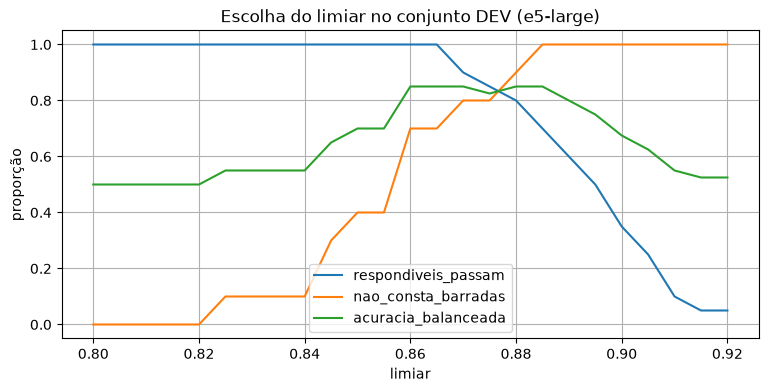

In [5]:
curva = pd.DataFrame(av.curva_limiar(idx, DEV, [round(0.80 + 0.005 * i, 3) for i in range(25)]))
curva.to_csv(RAIZ / 'avaliacao' / 'curva_limiar_dev.csv', index=False)
import matplotlib.pyplot as plt
ax = curva.plot(x='limiar', y=['respondiveis_passam', 'nao_consta_barradas', 'acuracia_balanceada'], figsize=(9, 4), grid=True)
ax.set_ylabel('proporção'); ax.set_title('Escolha do limiar no conjunto DEV (e5-large)')
plt.savefig(RAIZ / 'avaliacao' / 'curva_limiar_dev.png', dpi=120, bbox_inches='tight')
curva[(curva.limiar >= 0.84) & (curva.limiar <= 0.89)]

In [6]:
melhor = curva[curva.acuracia_balanceada == curva.acuracia_balanceada.max()].iloc[0]
print('Menor limiar com a maior acurácia balanceada no DEV:', melhor.to_dict())

Menor limiar com a maior acurácia balanceada no DEV: {'limiar': 0.86, 'respondiveis_passam': 1.0, 'nao_consta_barradas': 0.7, 'acuracia_balanceada': 0.85}


**Justificativa do limiar 0,86 (escolhido no DEV):** é o menor limiar com a maior acurácia balanceada sem perder nenhuma pergunta respondível. Subir mais barra mais "não consta", mas começa a negar respostas a quem precisa; as "não consta" que passam do limiar ainda enfrentam a instrução de recusa e, no agente, as verificações. As que passam são justamente as armadilhas do mesmo assunto (ex.: horário de um posto de atendimento), que a busca sozinha não separa.

## Medida final no TESTE (nenhuma escolha é feita aqui)

In [7]:
r_teste = av.recall_at_k(idx, TESTE, (1, 3, 5))
c_teste = pd.DataFrame(av.curva_limiar(idx, TESTE, [0.86]))
final = pd.DataFrame([{'conjunto': 'teste (final)', **{k: v for k, v in r_teste.items() if k != 'detalhes'}, **c_teste.iloc[0].to_dict()}])
final.to_csv(RAIZ / 'avaliacao' / 'recall_teste_final.csv', index=False)
final

,conjunto,recall@1,recall@3,recall@5,limiar,respondiveis_passam,nao_consta_barradas,acuracia_balanceada
0,teste (final),0.733,0.967,1.0,0.86,0.933,0.8,0.867


In [8]:
det = pd.DataFrame(r_teste['detalhes'])
det['acertou_top3'] = det.apply(lambda d: bool(set(d['top'][:3]) & set(d['esperados'])), axis=1)
print('Perguntas do teste em que o trecho certo não veio no top-3 (só registro, não usado para ajustar):')
det[~det['acertou_top3']]

Perguntas do teste em que o trecho certo não veio no top-3 (só registro, não usado para ajustar):


,id,top,score_top1,esperados,acertou_top3
28,q39,"[sptrans-bilhete-estudante-037, sptrans-gratuidade-60-64-004, sptrans-gratuidade-60-64-011, sptrans-gratuidade-60-64...",0.8622,[sptrans-gratuidade-60-64-005],False
